In [46]:
import matplotlib.pyplot as plt    
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'   
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd                                               
import numpy as np                                         
from sklearn import svm,metrics                            
from sklearn.neighbors import KNeighborsClassifier   #분류
from sklearn.neighbors import KNeighborsRegressor    #예측
from sklearn.linear_model import LinearRegression    #예측
from sklearn.metrics import mean_absolute_error      #평균절대값오차 오차범위     
from sklearn.preprocessing import StandardScaler     #정규화 클래스 
from sklearn.model_selection import train_test_split       

In [47]:
#sep='\t' : 분리형태, skiprows=1 : 1줄삭제, header=None: 컬럼제목없이
df =pd.read_csv('data/study.csv',sep="\t")
df.head(5)

,our,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22


In [48]:
# 데이터 전처리
# data =df['our'].values
# label =df['score'].values
data = df.iloc[:,:-1].values
# data = df.iloc[:,0].values
#시간
# data = np.reshape(-1,1)
label = df.iloc[:,1:].values

In [49]:
#학습데이터,테스트데이터분리
train_data,test_data,train_label,test_label = train_test_split(data,label)

In [50]:
#데이터학습
lr =LinearRegression()
lr.fit(train_data,train_label)

#테스트 데이터예측
predict = lr.predict(test_data)
print("예측점수: ",predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("train정확도 :",score)
print("test정확도 :",score2)

예측점수:  [[60.20692286]
 [63.4506244 ]
 [ 2.90152907]
 [90.48147052]
 [72.10049516]]
train정확도 : 0.9726874251164133
test정확도 : 0.8866810052451277


In [51]:
# 점수입력
input1 = input('공부시간을 입력하세요.(예:7,10,0.9)')
input1=float(input1)
result =lr.predict([[input1]])
print("예측점수:",result)


예측점수: [[73.181729]]


In [52]:
#기울기,y절편확인
print('기울기:',lr.coef_)
print('y절편:',lr.intercept_)

기울기: [[10.81233845]]
y절편: [-2.50464015]


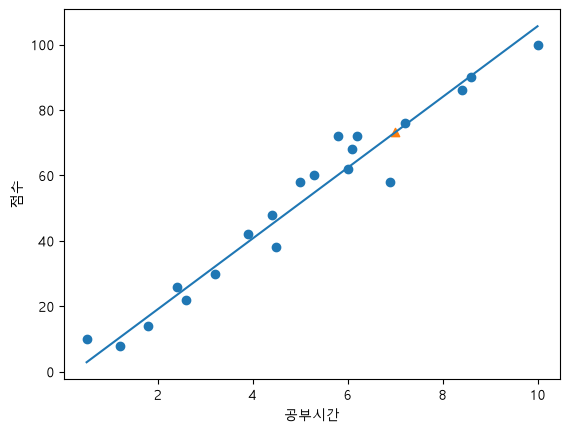

In [56]:
# 산점도 그래프
plt.scatter(data,label)
plt.scatter(input1,result,marker="^")

plt.plot([0.5,10],[0.5*lr.coef_[0]+lr.intercept_,10*lr.coef_[0]+lr.intercept_])
plt.xlabel("공부시간")
plt.ylabel("점수")
plt.show()